# MT-KAN PC with ANS

## Environment and dependencies

Recommended kernel: **Python (compression-eval GPU)**  
Managed interpreter: `/media/atleebugs/HDD/PythonLib/ml-envs/compression-eval/bin/python`

This notebook requires:

- `numpy>=1.24,<2`
- `matplotlib>=3.10,<4`
- `pandas>=2.2,<3`
- `scikit-learn>=1.5,<1.8`
- `seaborn>=0.13,<0.14`
- `PyYAML>=6,<7`
- `tqdm>=4.66,<5`
- `pykan==0.2.8`
- `torch==2.9.0+cu126`
- `compression-evaluation` (local editable project)

The next cell only checks dependencies; it deliberately never runs `pip`, upgrades packages, or reinstalls the project. The managed kernel already contains these packages. For a separate environment, run the following commands from the `notebooks/` directory, restart its kernel, and rerun the check:

```bash
python -m pip install "numpy>=1.24,<2" "matplotlib>=3.10,<4" "pandas>=2.2,<3" "scikit-learn>=1.5,<1.8" "seaborn>=0.13,<0.14" "PyYAML>=6,<7" "tqdm>=4.66,<5" "pykan==0.2.8"
python -m pip install torch==2.9.0 --index-url https://download.pytorch.org/whl/cu126
python -m pip install -e ..
```


In [ ]:
# Non-mutating dependency check (safe to run in every kernel)
from importlib.metadata import PackageNotFoundError, version
from importlib.util import find_spec
import sys

REQUIRED_DISTRIBUTIONS = {'numpy': 'numpy', 'matplotlib': 'matplotlib', 'pandas': 'pandas', 'scikit-learn': 'sklearn', 'seaborn': 'seaborn', 'PyYAML': 'yaml', 'tqdm': 'tqdm', 'pykan': 'kan', 'torch': 'torch', 'compression-evaluation': 'compression_evaluation'}
MANAGED_INTERPRETER = '/media/atleebugs/HDD/PythonLib/ml-envs/compression-eval/bin/python'

print(f"Kernel Python: {sys.executable}")
if sys.executable != MANAGED_INTERPRETER:
    print("Note: this is not the managed compression-eval GPU interpreter.")

missing = []
for distribution, import_name in REQUIRED_DISTRIBUTIONS.items():
    if find_spec(import_name) is None:
        missing.append(distribution)
        continue
    try:
        installed = version(distribution)
    except PackageNotFoundError:
        installed = "available (version metadata not found)"
    print(f"{distribution}: {installed}")

if missing:
    raise RuntimeError(
        "Missing notebook dependencies: " + ", ".join(missing) +
        ". Select 'Python (compression-eval GPU)' or use the documented commands above in a separate environment."
    )
print("Dependency check passed; no packages were changed.")

import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")


This notebook covers evaluation of Multivariate Temporal - Kolmogrov Arnold Networks based Predicitve Coding with Asymmetric Numeral Systems using the compression-evaluation package.

The Predictive Coder and Decoder evaluated in this notebook follows the following structure,

![Encoder](images/PC_processing-Encoder-Point-Predictor.drawio.png)


![Decoder](images/PC_processing-Decoder-Point-Predictor.drawio.png)

Where each encoder and decoder encodes and decodes a vector of readings (multiple readings that show correlations to one another)

## Import datasets

For evaluation of this predictive coding technique several correlated dataseries are used under the assumption that correlations could potentially improve mutual prediction accuracy.

In [3]:
import pandas as pd

raw_df = pd.read_csv(r'..\datasets\AriviyalN_Data.csv', header=2)

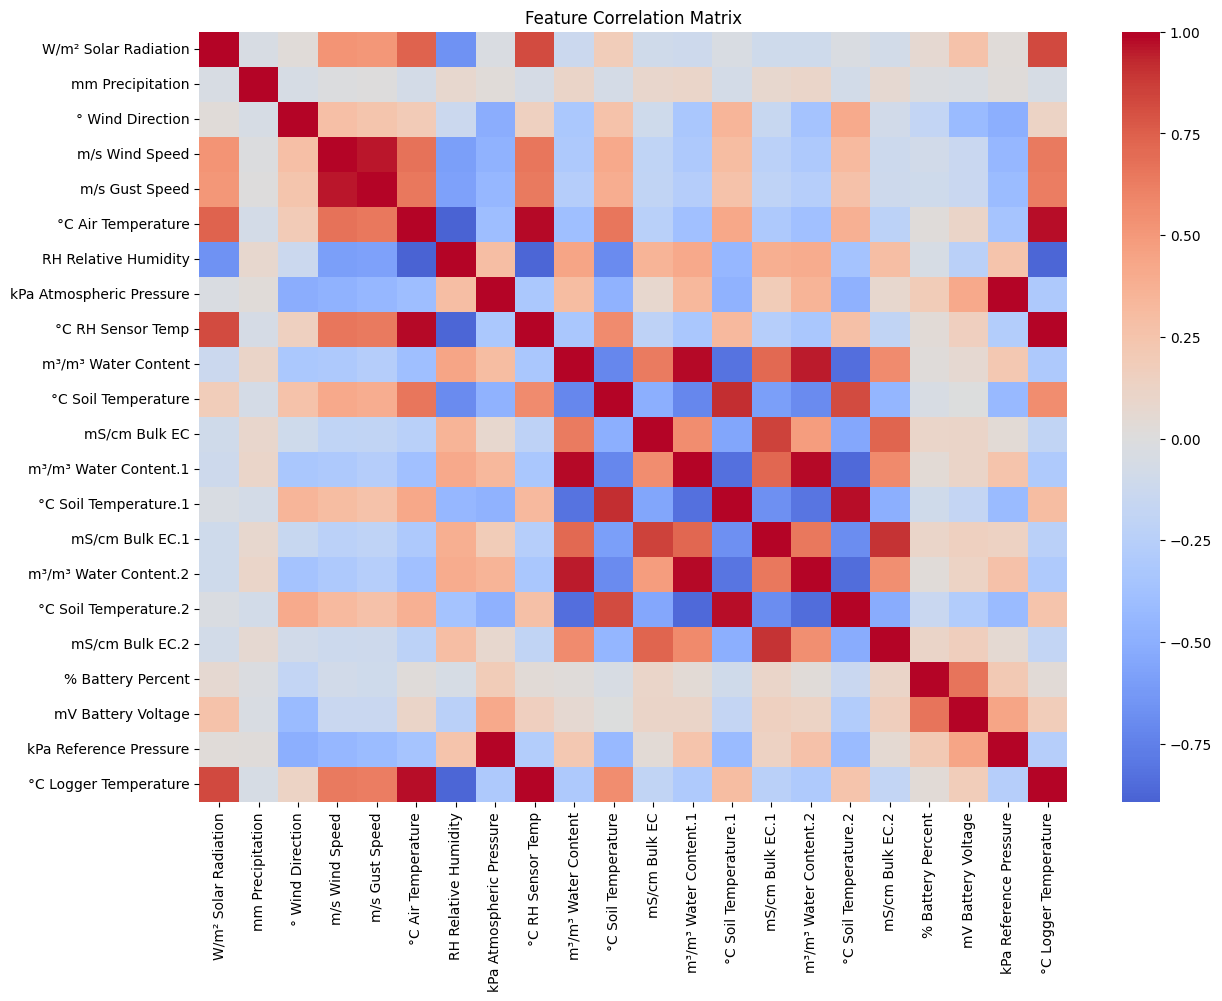

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# clean up column names
raw_df.columns = raw_df.columns.str.strip()

# parse timestamp and sort
raw_df['Timestamp'] = pd.to_datetime(raw_df['Timestamp'], dayfirst=True)
raw_df = raw_df.sort_values('Timestamp').reset_index(drop=True)

# drop unwanted columns if they exist
drop_cols = [
    'Lightning Activity', 'km Lightning Distance', '° X-axis Level',
    '° Y-axis Level', 'mm/h Max Precip Rate'
]
data_df = raw_df.drop(columns=[c for c in drop_cols if c in raw_df.columns])

# select numeric columns only
num_df = data_df.select_dtypes(include='number')

# compute correlation matrix
corr = num_df.corr()

# plot heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Feature Correlation Matrix')
plt.show()

As observed here,

1. Humidity and air temperature has a strong negative correlation
2. Soil water content and soil temperature has a strong (relatively weaker than 1) negative correlation
3. Soil temperature and air temperature has a weak positive correlation

These relationships will be used in following sections to improve mutual prediction (and thus compression ratio) of these sesor data. Though there are stronger relationships, sensor readings of same type will not be paired together given that if worse relationships can produce good accuracy, by inference, better accuracy can be expected for more strongly related readings (in some cases, even a single predictor could be enough). Thus for case study of MT-KAN based predictive coding, readings of,

1. Humidity
2. Air Temperature
3. Soil Temperature
4. Soil Water Content

would be grouped together.

In [5]:
# Extract the three dataseries
air_temp = raw_df["°C Air Temperature"]
humidity = raw_df["RH Relative Humidity"]
water_content = raw_df["m³/m³ Water Content"]
soil_temp = raw_df["°C Soil Temperature"]

In [6]:
def print_invalids_count():
    print("Air Temperature NaNs:", air_temp.isna().sum())
    print("Relative Humidity NaNs:", humidity.isna().sum())
    print("Water Content NaNs:", water_content.isna().sum())
    print("Soil Temperatre NaNs:", soil_temp.isna().sum())

    print("Air Temperature Nulls:", air_temp.isnull().sum())
    print("Relative Humidity Nulls:", humidity.isnull().sum())
    print("Water Content Nulls:", water_content.isnull().sum())
    print("Soil Temperatre Nulls:", soil_temp.isnull().sum())

def fill_with_mean(series):
    # Find indices where value is NaN or null
    nan_indices = series[series.isna() | series.isnull()].index
    for idx in nan_indices:
        prev_idx = idx - 1
        next_idx = idx + 1
        # Find previous non-null value
        while prev_idx >= 0 and (pd.isna(series.iloc[prev_idx]) or pd.isnull(series.iloc[prev_idx])):
            prev_idx -= 1
        # Find next non-null value
        while next_idx < len(series) and (pd.isna(series.iloc[next_idx]) or pd.isnull(series.iloc[next_idx])):
            next_idx += 1
        # If both indices are valid, fill with their mean
        if prev_idx >= 0 and next_idx < len(series):
            mean_val = (series.iloc[prev_idx] + series.iloc[next_idx]) / 2
            series.iloc[idx] = mean_val
    return series

# Before filling
print("Before cleanup: ")
print_invalids_count()

air_temp = fill_with_mean(air_temp)
humidity = fill_with_mean(humidity)
water_content = fill_with_mean(water_content)
soil_temp = fill_with_mean(soil_temp)

# After filling
print("\nAfter cleanup: ")
print_invalids_count()

Before cleanup: 
Air Temperature NaNs: 1
Relative Humidity NaNs: 1
Water Content NaNs: 1
Soil Temperatre NaNs: 1
Air Temperature Nulls: 1
Relative Humidity Nulls: 1
Water Content Nulls: 1
Soil Temperatre Nulls: 1

After cleanup: 
Air Temperature NaNs: 0
Relative Humidity NaNs: 0
Water Content NaNs: 0
Soil Temperatre NaNs: 0
Air Temperature Nulls: 0
Relative Humidity Nulls: 0
Water Content Nulls: 0
Soil Temperatre Nulls: 0


In [7]:
from compression_evaluation import methods as util_methods
import numpy as np

# convert to dataseries to set of timseries datasets
data_series_air_8_3 = util_methods.build_time_series_dataset(air_temp, 8, 3, shuffle=False)
data_series_hum_8_3 = util_methods.build_time_series_dataset(humidity, 8, 3, shuffle=False)
data_series_wat_8_3 = util_methods.build_time_series_dataset(water_content, 8, 3, shuffle=False)
data_series_soi_8_3 = util_methods.build_time_series_dataset(soil_temp, 8, 3, shuffle=False)

# group them together (serially)
X_air_8_3, Y_air_8_3 = data_series_air_8_3
X_hum_8_3, Y_hum_8_3 = data_series_hum_8_3
X_wat_8_3, Y_wat_8_3 = data_series_wat_8_3
X_soi_8_3, Y_soi_8_3 = data_series_soi_8_3

# ensure all have the same number of samples
n_samples = min(len(X_air_8_3), len(X_hum_8_3), len(X_wat_8_3), len(X_soi_8_3))

# slice to same number of samples
X_air, Y_air = X_air_8_3[:n_samples], Y_air_8_3[:n_samples]
X_hum, Y_hum = X_hum_8_3[:n_samples], Y_hum_8_3[:n_samples]
X_wat, Y_wat = X_wat_8_3[:n_samples], Y_wat_8_3[:n_samples]
X_soi, Y_soi = X_soi_8_3[:n_samples], Y_soi_8_3[:n_samples]

# concatenate serially
data_series_all_8_3 = (
    np.concatenate([X_air, X_hum, X_wat, X_soi], axis=1),  # X_combined
    np.concatenate([Y_air, Y_hum, Y_wat, Y_soi], axis=1)   # Y_combined
)


In [8]:
# train MTKAN model
from kan.MultKAN import KAN
import torch

torch.set_default_dtype(torch.float64)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# Unpack combined dataset
X_all_8_3, y_all_8_3 = data_series_all_8_3

# Split into training and validation sets (example: 80/20 split)
n_train = int(0.8 * len(X_all_8_3))
X_train_8_3 = torch.tensor(X_all_8_3[:n_train], dtype=torch.float64, device=device)
y_train_8_3 = torch.tensor(y_all_8_3[:n_train], dtype=torch.float64, device=device)

X_valid_8_3 = torch.tensor(X_all_8_3[n_train:], dtype=torch.float64, device=device)
y_valid_8_3 = torch.tensor(y_all_8_3[n_train:], dtype=torch.float64, device=device)

# Create dataset dictionary for KAN
dataset_all_8_3 = {
    'train_input': X_train_8_3,
    'train_label': y_train_8_3,
    'test_input': X_valid_8_3,
    'test_label': y_valid_8_3
}

# Initialize KAN model (no hidden layers: input_size -> output_size)
air_all_8_3_kan = KAN(width=[32, 12], grid=1, k=1, seed=42, device=device)

# Fit KAN model
air_all_8_3_kan.fit(dataset_all_8_3)

# Predict
y_train_8_3_pred = air_all_8_3_kan(dataset_all_8_3['train_input'])
y_valid_8_3_pred = air_all_8_3_kan(dataset_all_8_3['test_input'])

Using device: cpu
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 2.48e-01 | test_loss: 2.17e-01 | reg: 3.83e+01 | : 100%|█| 100/100 [14:26<00:00,  8.66


saving model version 0.1


In [9]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_valid_8_3.detach().numpy(), y_valid_8_3_pred.detach().numpy())
print("Training MSE (5 input dim):", mse)

Training MSE (5 input dim): 0.04700277214837653


In [10]:
# extract residuals and observe distribution
residuals_train_8_3 = y_train_8_3 - y_train_8_3_pred
residuals_valid_8_3 = y_valid_8_3 - y_valid_8_3_pred

# Each series has output_size = 3, total 4 series, concatenated serially in combined dataset
output_size = 3
n_series = 4

def split_residuals(residuals, output_size=3, n_series=4):
    split_list = []
    for i in range(n_series):
        split_list.append(residuals[:, i*output_size:(i+1)*output_size])
    return split_list

# Train residuals
residuals_train_air_8_3, residuals_train_hum_8_3, residuals_train_wat_8_3, residuals_train_soi_8_3 = \
    split_residuals(residuals_train_8_3, output_size, n_series)

# Validation residuals
residuals_valid_air_8_3, residuals_valid_hum_8_3, residuals_valid_wat_8_3, residuals_valid_soi_8_3 = \
    split_residuals(residuals_valid_8_3, output_size, n_series)

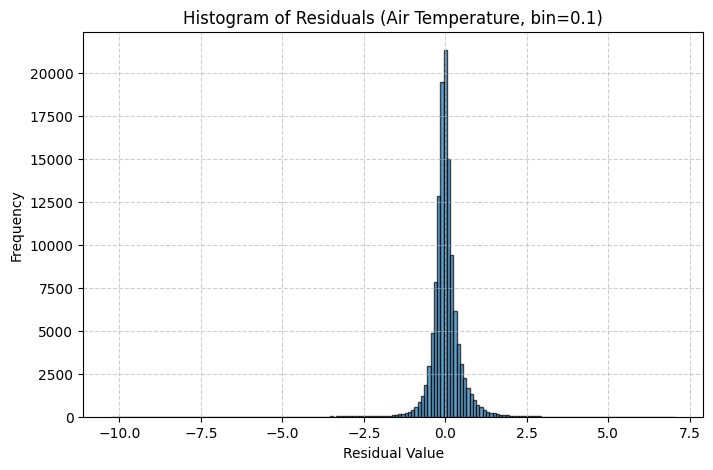

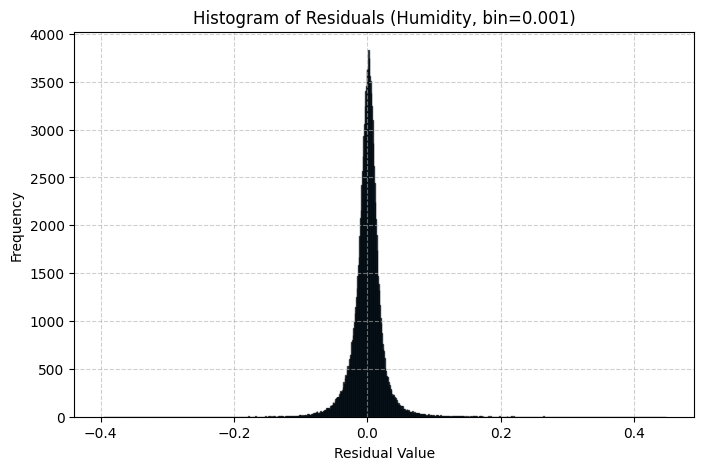

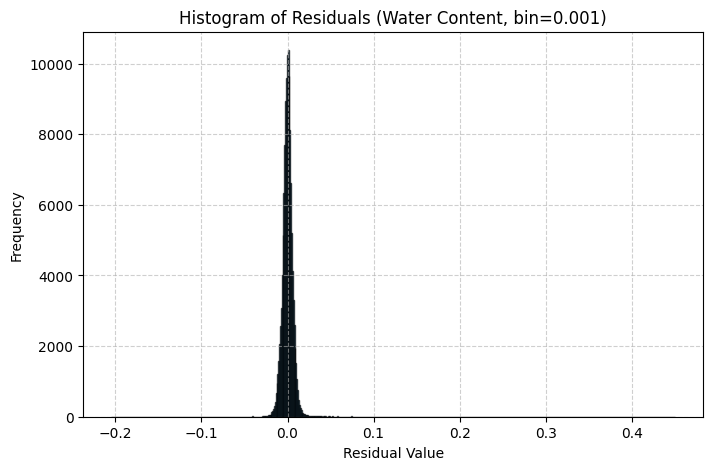

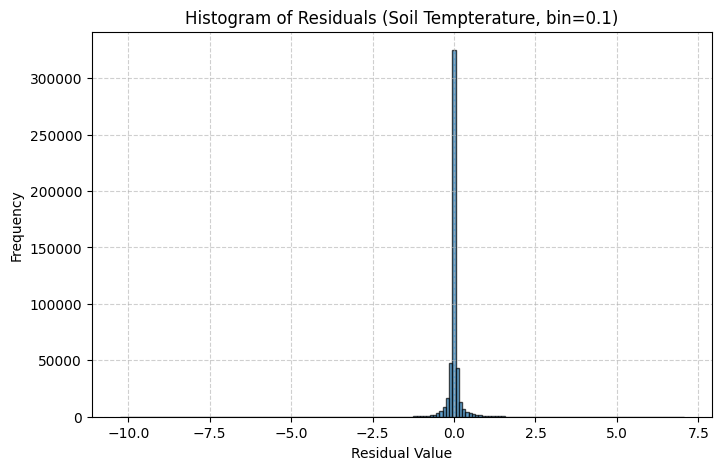

In [19]:
# seperate into bins and observe distribution
air_bin_size = 0.1
hum_bin_size = 0.001
wat_bin_size = 0.001
soi_bin_size = 0.1

# generate bins to fit residuals (5 bin padding on either sides)
residuals_train_8_3_air_np = residuals_train_air_8_3.detach().numpy()
air_8_3_bins = np.arange(residuals_train_8_3_air_np.min() - 5 * air_bin_size, residuals_train_8_3_air_np.max() + 5 * air_bin_size, air_bin_size)

residuals_train_8_3_hum_np = residuals_train_hum_8_3.detach().numpy()
hum_8_3_bins = np.arange(residuals_train_8_3_hum_np.min() - 5 * hum_bin_size, residuals_train_8_3_hum_np.max() + 5 * hum_bin_size, hum_bin_size)

residuals_train_8_3_wat_np = residuals_train_wat_8_3.detach().numpy()
wat_8_3_bins = np.arange(residuals_train_8_3_wat_np.min() - 5 * wat_bin_size, residuals_train_8_3_wat_np.max() + 5 * wat_bin_size, wat_bin_size)

residuals_train_8_3_soi_np = residuals_train_8_3.detach().numpy()
soi_8_3_bins = np.arange(residuals_train_8_3_soi_np.min() - 5 * soi_bin_size, residuals_train_8_3_soi_np.max() + 5 * soi_bin_size, soi_bin_size)

# get counts and bin edges
air_8_3_counts, air_8_3_bin_edges = np.histogram(residuals_train_8_3_air_np, bins=air_8_3_bins)
air_8_3_bin_centers = (air_8_3_bin_edges[:-1] + air_8_3_bin_edges[1:]) / 2

hum_8_3_counts, hum_8_3_bin_edges = np.histogram(residuals_train_8_3_hum_np, bins=hum_8_3_bins)
hum_8_3_bin_centers = (hum_8_3_bin_edges[:-1] + hum_8_3_bin_edges[1:]) / 2

wat_8_3_counts, wat_8_3_bin_edges = np.histogram(residuals_train_8_3_wat_np, bins=wat_8_3_bins)
wat_8_3_bin_centers = (wat_8_3_bin_edges[:-1] + wat_8_3_bin_edges[1:]) / 2

soi_8_3_counts, soi_8_3_bin_edges = np.histogram(residuals_train_8_3_soi_np, bins=soi_8_3_bins)
soi_8_3_bin_centers = (soi_8_3_bin_edges[:-1] + soi_8_3_bin_edges[1:]) / 2

# plot histogram (reusing same bins)
plt.figure(figsize=(8, 5))
plt.bar(air_8_3_bin_centers, air_8_3_counts, width=air_bin_size, edgecolor='black', alpha=0.7)
plt.title("Histogram of Residuals (Air Temperature, bin=0.1)")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(hum_8_3_bin_centers, hum_8_3_counts, width=hum_bin_size, edgecolor='black', alpha=0.7)
plt.title("Histogram of Residuals (Humidity, bin=0.001)")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(wat_8_3_bin_centers, wat_8_3_counts, width=wat_bin_size, edgecolor='black', alpha=0.7)
plt.title("Histogram of Residuals (Water Content, bin=0.001)")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(soi_8_3_bin_centers, soi_8_3_counts, width=soi_bin_size, edgecolor='black', alpha=0.7)
plt.title("Histogram of Residuals (Soil Tempterature, bin=0.1)")
plt.xlabel("Residual Value")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [12]:
from compression_evaluation import classes as util_classes

In [13]:
# get frequency counts and fit to seperate quantizers
air_8_3_padded_counts = air_8_3_counts + 1

# fit quantizer
air_8_3_quantizer = util_classes.UniformQuantizer(air_bin_size, len(air_8_3_bins), air_8_3_bin_edges[1], True)

# map bin centers to symbols
air_8_3_symbols = [air_8_3_quantizer.value_to_symbol(res) for res in air_8_3_bin_centers]

In [ ]:
# sanity check
print(air_8_3_bin_edges)

In [ ]:
# reduce frequency counts and fit ANSCoders


In [ ]:
# fit all to MultivariatePCEncoder and MultivariatePCDecoder

In [ ]:
# evaluate using Multivariate evaluator